# Overall Model Comparison and Final Selection

This notebook combines the standardized results for Logistic Regression,
Decision Tree, Random Forest, and Gradient Boosting. It compares CV performance,
generalization gaps, tuning effects, and the feature experiment to support
the group's final model selection.

## 1. Load Model Results

Load the saved CV and test results. Model selection is guided by training
cross-validation; test results are reported as final evaluation evidence.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)

OUTPUT_DIR = ROOT / "06_Model_Evaluation"

model_files = [
    "logistic_regression",
    "decision_tree",
    "random_forest",
    "gradient_boosting",
]

all_cv_results = pd.concat(
    [
        pd.read_csv(OUTPUT_DIR / f"{name}_cv_results.csv")
        for name in model_files
    ],
    ignore_index=True
)

all_test_results = pd.concat(
    [
        pd.read_csv(OUTPUT_DIR / f"{name}_test_results.csv")
        for name in model_files
    ],
    ignore_index=True
)

print(f"CV result rows: {len(all_cv_results)}")
print(f"Test result rows: {len(all_test_results)}")
display(all_test_results[["model", "version"]])

CV result rows: 42
Test result rows: 7


,model,version
0,Logistic Regression,Baseline
1,Decision Tree,Baseline
2,Decision Tree,Tuned
3,Random Forest,Baseline
4,Random Forest,Tuned
5,Gradient Boosting,Baseline
6,Gradient Boosting,Tuned


## 2. Baseline Model Comparison

Compare mean cross-validation metrics for the four baseline models under
the shared evaluation setup. Sort by CV F1, the common tuning objective.

In [2]:
metric_order = [
    "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"
]

baseline_comparison = (
    all_cv_results.loc[all_cv_results["version"] == "Baseline"]
    .pivot(index="model", columns="metric", values="cv_mean")
    .reindex(columns=metric_order)
    .sort_values("f1", ascending=False)
)

display(baseline_comparison.round(4))

baseline_comparison.to_csv(
    OUTPUT_DIR / "baseline_model_comparison_cv.csv"
)

metric,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Random Forest,0.8888,0.8805,0.8101,0.8438,0.9563,0.9378
Decision Tree,0.8541,0.8020,0.8052,0.8036,0.8463,0.7224
Gradient Boosting,0.8504,0.8391,0.7381,0.7854,0.9256,0.8939
Logistic Regression,0.8209,0.8058,0.6814,0.7383,0.9039,0.8657


## 3. Overall Cross-Validation Comparison

Compare all seven model configurations using mean CV metrics and F1
variability. Tuned scores reflect parameter selection and are not independent
nested-CV estimates.

In [3]:
overall_cv_comparison = (
    all_cv_results
    .pivot(
        index=["model", "version"],
        columns="metric",
        values="cv_mean"
    )
    .reindex(columns=metric_order)
)

f1_std = (
    all_cv_results.loc[all_cv_results["metric"] == "f1"]
    .set_index(["model", "version"])["cv_std"]
)

overall_cv_comparison["f1_cv_std"] = f1_std
overall_cv_comparison = overall_cv_comparison.sort_values(
    "f1", ascending=False
)

display(overall_cv_comparison.round(4))
overall_cv_comparison.to_csv(
    OUTPUT_DIR / "overall_model_comparison_cv.csv"
)

metric                        accuracy  precision  recall      f1  roc_auc  \
model               version                                                  
Random Forest       Tuned       0.8902     0.8659  0.8328  0.8490   0.9576   
                    Baseline    0.8888     0.8805  0.8101  0.8438   0.9563   
Gradient Boosting   Tuned       0.8688     0.8435  0.7934  0.8177   0.9440   
Decision Tree       Baseline    0.8541     0.8020  0.8052  0.8036   0.8463   
Gradient Boosting   Baseline    0.8504     0.8391  0.7381  0.7854   0.9256   
Decision Tree       Tuned       0.8452     0.8163  0.7518  0.7827   0.9223   
Logistic Regression Baseline    0.8209     0.8058  0.6814  0.7383   0.9039   

metric                        pr_auc  f1_cv_std  
model               version                      
Random Forest       Tuned     0.9394     0.0017  
                    Baseline  0.9378     0.0023  
Gradient Boosting   Tuned     0.9181     0.0016  
Decision Tree       Baseline  0.7224     0.0036  
Gradient Boosting   Baseline  0.8939     0.0019  
Decision Tree       Tuned     0.8715     0.0037  
Logistic Regression Baseline  0.8657     0.0039

## 4. Generalization and Overfitting Comparison

Compare training and validation F1 for every configuration. Interpret
the generalization gap alongside validation performance; a small gap
alone does not establish that a model is the best predictor.

In [4]:
generalization_comparison = all_cv_results.loc[
    all_cv_results["metric"] == "f1",
    ["model", "version", "train_mean", "cv_mean", "cv_std"]
].copy()

generalization_comparison["train_cv_gap"] = (
    generalization_comparison["train_mean"]
    - generalization_comparison["cv_mean"]
)

generalization_comparison = generalization_comparison.sort_values(
    "cv_mean", ascending=False
)

display(generalization_comparison.round(4))

generalization_comparison.to_csv(
    OUTPUT_DIR / "model_generalization_comparison.csv",
    index=False
)

,model,version,train_mean,cv_mean,cv_std,train_cv_gap
27,Random Forest,Tuned,0.9868,0.8490,0.0017,0.1378
21,Random Forest,Baseline,0.9942,0.8438,0.0023,0.1504
39,Gradient Boosting,Tuned,0.8291,0.8177,0.0016,0.0114
9,Decision Tree,Baseline,0.9942,0.8036,0.0036,0.1906
33,Gradient Boosting,Baseline,0.7868,0.7854,0.0019,0.0015
15,Decision Tree,Tuned,0.7861,0.7827,0.0037,0.0034
3,Logistic Regression,Baseline,0.7403,0.7383,0.0039,0.0020


**Interpretation:** The baseline Decision Tree has the largest F1 gap
(0.1906). Tuning reduces its gap to 0.0034, but validation F1 also decreases.

Random Forest tuning reduces the gap from 0.1504 to 0.1378 and improves
validation F1 to 0.8490. A substantial gap remains despite its leading
CV performance.

Gradient Boosting tuning improves validation F1 from 0.7854 to 0.8177,
while increasing its gap from 0.0015 to 0.0114. Logistic Regression has
a small gap but the lowest validation F1 among the evaluated configurations.

## 5. Effect of Hyperparameter Tuning

Calculate changes in mean CV metrics between baseline and tuned versions.
Positive values indicate improvement in the reported metric.

In [5]:
cv_means = all_cv_results.pivot(
    index=["model", "version"],
    columns="metric",
    values="cv_mean"
).reindex(columns=metric_order)

tuning_effect = (
    cv_means.xs("Tuned", level="version")
    - cv_means.xs("Baseline", level="version")
).dropna(how="all")

display(tuning_effect.round(4))

tuning_effect.to_csv(OUTPUT_DIR / "model_tuning_effect_cv.csv")

metric,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Decision Tree,-0.0088,0.0143,-0.0533,-0.0209,0.0760,0.1491
Gradient Boosting,0.0184,0.0043,0.0553,0.0323,0.0185,0.0242
Random Forest,0.0014,-0.0146,0.0227,0.0052,0.0013,0.0016


## 6. Feature Experiment Summary

Review the Random Forest experiment that removed arrival week number and
day-of-month. Compare configurations under the same baseline model and CV
conditions to assess the feature change.

In [6]:
feature_experiment_cv = pd.read_csv(
    OUTPUT_DIR / "random_forest_feature_experiment_cv_results.csv"
)

feature_experiment_comparison = feature_experiment_cv.pivot(
    index="metric",
    columns="version",
    values="cv_mean"
).reindex(metric_order)

feature_experiment_comparison["change"] = (
    feature_experiment_comparison["Calendar fields removed"]
    - feature_experiment_comparison["Baseline"]
)

display(feature_experiment_comparison.round(4))

feature_experiment_comparison.to_csv(
    OUTPUT_DIR / "feature_experiment_summary_cv.csv"
)

version,Baseline,Calendar fields removed,change
metric,,,
accuracy,0.8888,0.8865,-0.0023
precision,0.8805,0.8748,-0.0057
recall,0.8101,0.8099,-0.0002
f1,0.8438,0.8411,-0.0028
roc_auc,0.9563,0.9548,-0.0014
pr_auc,0.9378,0.9358,-0.0020


**Feature experiment conclusion:** Removing arrival week number and
day-of-month reduced mean CV F1 from 0.8438 to 0.8411. The other reported
metrics also declined slightly. This experiment provides no evidence of
improvement, so the reference feature set is retained.

## 7. Final Test Results

Present the saved test metrics for all finalized configurations.
These results are reported separately from the CV evidence used for selection.

In [7]:
test_report = all_test_results[
    ["model", "version", *metric_order, "fit_seconds"]
].copy()

display(test_report.round(4))

test_report.to_csv(
    OUTPUT_DIR / "overall_model_comparison_test.csv",
    index=False
)

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Logistic Regression,Baseline,0.8243,0.8131,0.6832,0.7425,0.9051,0.8684,1.7032
1,Decision Tree,Baseline,0.8595,0.8075,0.8154,0.8114,0.8528,0.7316,7.8892
2,Decision Tree,Tuned,0.8462,0.8189,0.7513,0.7836,0.9226,0.8728,1.2798
3,Random Forest,Baseline,0.8937,0.8844,0.8206,0.8513,0.9602,0.9416,45.4335
4,Random Forest,Tuned,0.8935,0.8701,0.8379,0.8537,0.9609,0.9430,77.9566
5,Gradient Boosting,Baseline,0.8524,0.8428,0.7398,0.7879,0.9250,0.8938,13.9322
6,Gradient Boosting,Tuned,0.8691,0.8450,0.7923,0.8178,0.9446,0.9184,62.1298


## 8. Model Comparison Visualization

Plot mean CV F1 with ±1 fold standard deviation. These bars summarize
variation across folds; they are not confidence intervals.

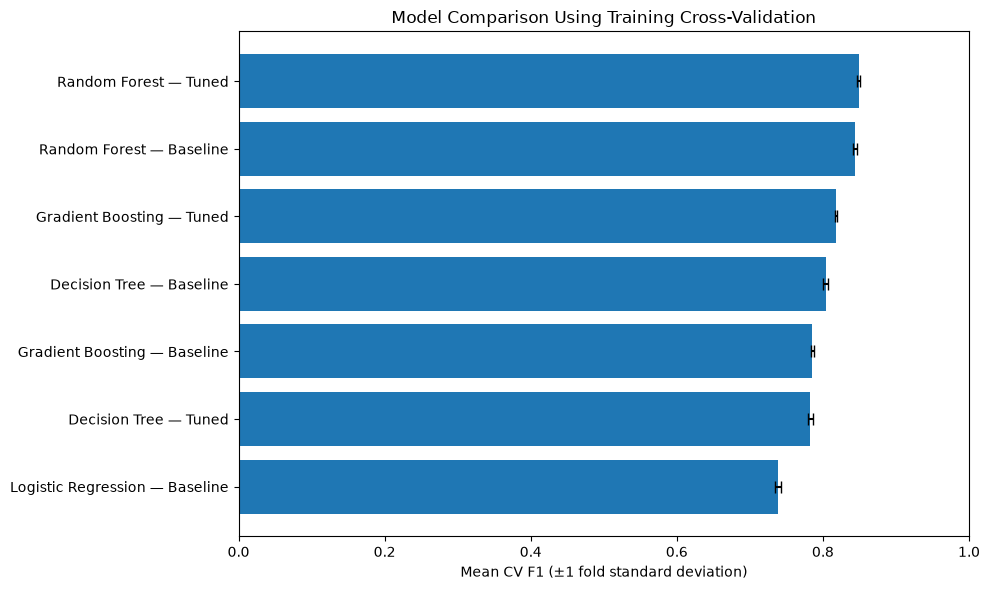

In [8]:
import matplotlib.pyplot as plt

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plot_data = generalization_comparison.sort_values("cv_mean").copy()
labels = plot_data["model"] + " — " + plot_data["version"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    labels,
    plot_data["cv_mean"],
    xerr=plot_data["cv_std"],
    capsize=4
)
ax.set_xlabel("Mean CV F1 (±1 fold standard deviation)")
ax.set_title("Model Comparison Using Training Cross-Validation")
ax.set_xlim(0, 1)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "overall_model_cv_f1_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

## 9. Final Model Selection Evidence

The tuned Random Forest is recommended for the group's final selection
because it achieved the highest mean CV F1 (0.8490), recall (0.8328),
ROC-AUC (0.9576), and average precision (0.9394) among the evaluated
configurations. This supports the objective of balancing cancellation
precision and recall.

Its training-validation F1 gap remains substantial at 0.1378. The model
therefore provides strong measured validation performance alongside a
remaining overfitting concern. Random Forest tuning used a stratified
30% training subset; the reported comparison CV used the full training set.

Saved test results show F1 of 0.8537 and recall of 0.8379, broadly consistent
with the CV results. These test metrics support reporting, rather than
further tuning or model selection.

The reference feature set is retained because removing the two calendar
fields did not improve validation performance. Final adoption should be
confirmed by the group.

## 10. Save the Recommended Model and Preprocessing Pipeline

Recreate the tuned Random Forest using the recorded hyperparameters and fit
the complete pipeline on the shared training partition only. Save the fitted
pipeline and metadata for the later backend stage.

The artifact is a recommended candidate pending the group's final approval.
The test set is not used for fitting.

In [9]:
import sys
import json
import joblib
import sklearn
from sklearn.ensemble import RandomForestClassifier

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    TEST_SIZE,
    CV_SPLITS,
    load_feature_dataset,
    split_feature_dataset,
    build_pipeline,
)

prepared = split_feature_dataset(load_feature_dataset())

selected_parameters = {
    "n_estimators": 100,
    "max_depth": 28,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": 0.5,
    "random_state": RANDOM_STATE,
    "n_jobs": 2,
}

recommended_pipeline = build_pipeline(
    RandomForestClassifier(**selected_parameters),
    prepared.X_train,
)

recommended_pipeline.fit(prepared.X_train, prepared.y_train)

MODEL_DIR = OUTPUT_DIR / "Models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "tuned_random_forest_pipeline.joblib"
joblib.dump(recommended_pipeline, model_path, compress=3)

metadata = {
    "model": "Random Forest",
    "version": "Tuned",
    "selection_status": "Recommended; pending group approval",
    "parameters": selected_parameters,
    "predictor_columns": prepared.X_train.columns.tolist(),
    "target": "is_canceled",
    "positive_class": 1,
    "training_rows": len(prepared.X_train),
    "test_size": TEST_SIZE,
    "cv_folds": CV_SPLITS,
    "selection_metric": "CV F1",
    "sklearn_version": sklearn.__version__,
}

(MODEL_DIR / "tuned_random_forest_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

# Check that saving and loading preserves predictions.
loaded_pipeline = joblib.load(model_path)
sample = prepared.X_train.head(20)

assert (
    loaded_pipeline.predict(sample)
    == recommended_pipeline.predict(sample)
).all()

print(f"Saved pipeline: {model_path.relative_to(ROOT)}")
print("Metadata saved. Reload prediction check passed.")

Saved pipeline: 06_Model_Evaluation\Models\tuned_random_forest_pipeline.joblib
Metadata saved. Reload prediction check passed.


## 11. Conclusion

The four model families were compared using the shared split, preprocessing,
cross-validation strategy, and metrics. Tuned Random Forest achieved the
highest mean CV F1 and is recommended for group approval, while its remaining
training-validation gap is documented.

Comparison tables, figures, hyperparameters, and the fitted model with
preprocessing have been saved for the later backend stage.